# Industrial Defect Detection — Dataset Exploration

## Objective

The goal of this project is to build a deep learning model that can classify different types of industrial surface defects from images.

## Dataset

We are using the NEU Surface Defect Database, which contains images of steel surface defects belonging to six defect categories:

- Crazing
- Inclusion
- Patches
- Pitted Surface
- Rolled-in Scale
- Scratches

## Project Pipeline

1. Dataset Exploration
2. Data Preprocessing
3. Train / Validation / Test Split
4. CNN / Transfer Learning
5. Model Training
6. Model Evaluation
7. Model Deployment

In [1]:
import os

In [2]:
os.getcwd()

'd:\\Career_Journey\\Projects\\Industrial_Defect_Detection\\Notebooks'

In [3]:
os.path.dirname(os.getcwd())

'd:\\Career_Journey\\Projects\\Industrial_Defect_Detection'

In [4]:
data_path = os.path.join(os.path.dirname(os.getcwd()), "Data")

In [5]:
data_path

'd:\\Career_Journey\\Projects\\Industrial_Defect_Detection\\Data'

In [6]:
raw_path = os.path.join(data_path, "Raw")

In [7]:
raw_path

'd:\\Career_Journey\\Projects\\Industrial_Defect_Detection\\Data\\Raw'

In [8]:
dataset_path = os.path.join(raw_path, "NEU-DET")

In [9]:
dataset_path

'd:\\Career_Journey\\Projects\\Industrial_Defect_Detection\\Data\\Raw\\NEU-DET'

In [10]:
os.listdir(dataset_path)

['train', 'validation']

In [11]:
os.listdir(os.path.join(dataset_path, "train"))

['annotations', 'images']

In [12]:
os.listdir(os.path.join(dataset_path, "train", "images"))[:10]

['crazing',
 'inclusion',
 'patches',
 'pitted_surface',
 'rolled-in_scale',
 'scratches']

In [13]:
train_images_path = os.path.join(dataset_path, "train", "images")

In [14]:
os.listdir(train_images_path)

['crazing',
 'inclusion',
 'patches',
 'pitted_surface',
 'rolled-in_scale',
 'scratches']

In [15]:
for class_name in os.listdir(train_images_path):
    class_path = os.path.join(train_images_path, class_name)
    print(class_name, len(os.listdir(class_path)))

crazing 240
inclusion 240
patches 240
pitted_surface 240
rolled-in_scale 240
scratches 240


In [16]:
validation_images_path = os.path.join(dataset_path, "validation", "images")

In [17]:
for class_name in os.listdir(validation_images_path):
    class_path = os.path.join(validation_images_path, class_name)
    print(class_name, len(os.listdir(class_path)))

crazing 60
inclusion 60
patches 60
pitted_surface 60
rolled-in_scale 60
scratches 60


In [18]:
import matplotlib.pyplot as plt
from PIL import Image

In [19]:
crazing_path = os.path.join(train_images_path, "crazing")

In [20]:
crazing_image = os.listdir(crazing_path)[0]

In [21]:
crazing_image

'crazing_1.jpg'

In [22]:
crazing_image_path = os.path.join(crazing_path, crazing_image)

In [23]:
crazing_image_path

'd:\\Career_Journey\\Projects\\Industrial_Defect_Detection\\Data\\Raw\\NEU-DET\\train\\images\\crazing\\crazing_1.jpg'

In [24]:
image = Image.open(crazing_image_path)

In [25]:
image.size

(200, 200)

In [26]:
image.mode

'RGB'

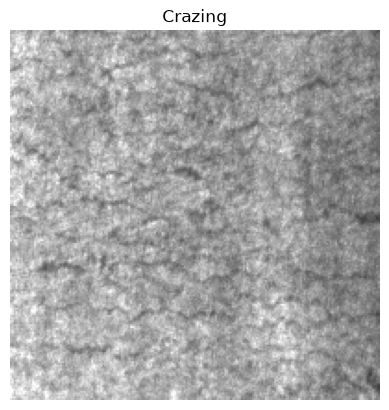

In [27]:
plt.imshow(image)
plt.title("Crazing")
plt.axis("off")
plt.show()

In [28]:
classes = os.listdir(train_images_path)

print(classes)

['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


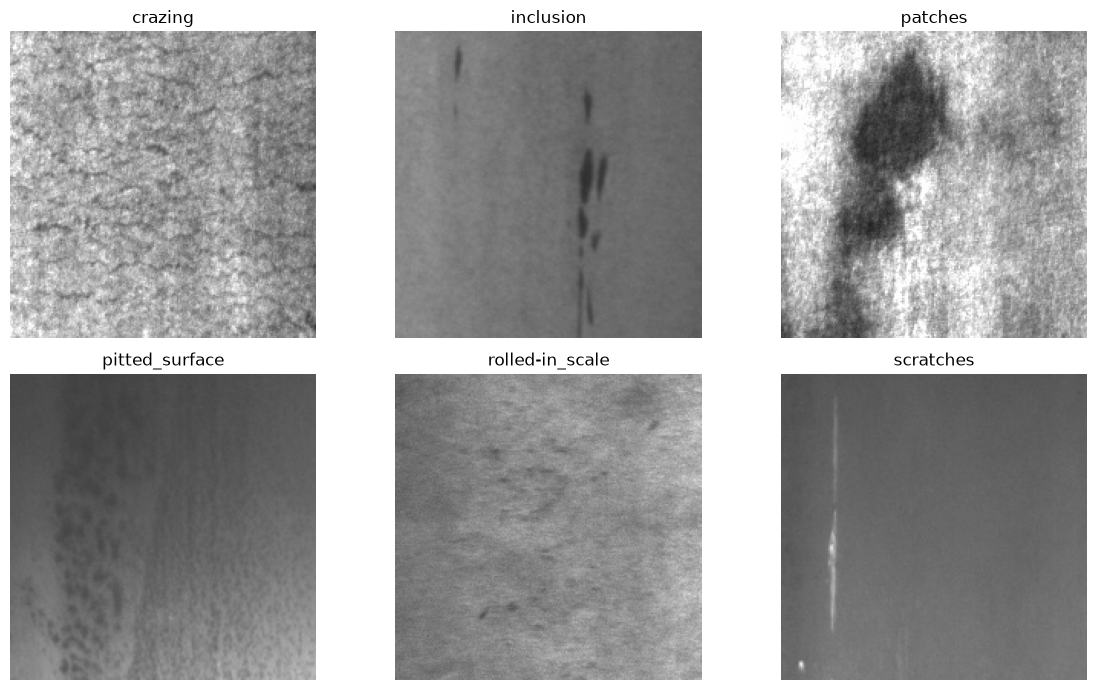

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, class_name in zip(axes.ravel(), classes):
    class_path = os.path.join(train_images_path, class_name)
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    img = Image.open(image_path)

    ax.imshow(img)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [30]:
import numpy as np

In [31]:
image_array = np.array(image)

image_array.shape

(200, 200, 3)

In [32]:
image_array.dtype

dtype('uint8')

In [33]:
image_array.min()

np.uint8(60)

In [34]:
image_array.max()

np.uint8(255)

In [35]:
class_to_index = {class_name: index for index, class_name in enumerate(classes)}

In [36]:
class_to_index

{'crazing': 0,
 'inclusion': 1,
 'patches': 2,
 'pitted_surface': 3,
 'rolled-in_scale': 4,
 'scratches': 5}

In [37]:
import torch

print(torch.__version__)

2.14.0+cpu


In [38]:
import sys

print(sys.executable)
print(sys.version)

d:\Career_Journey\Projects\Industrial_Defect_Detection\.venv\Scripts\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [39]:
import pip

print(pip.__version__)

25.0.1


In [40]:
import sys

print(sys.executable)
print(sys.version)

d:\Career_Journey\Projects\Industrial_Defect_Detection\.venv\Scripts\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [41]:
import sys

print(sys.executable)
print(sys.version)

d:\Career_Journey\Projects\Industrial_Defect_Detection\.venv\Scripts\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [42]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.14.0+cpu
Torchvision: 0.29.0+cpu


In [43]:
from torchvision import transforms

to_tensor = transforms.ToTensor()

image_tensor = to_tensor(image)

print(image_tensor.shape)
print(image_tensor.dtype)

torch.Size([3, 200, 200])
torch.float32


In [44]:
print(image_tensor.min())
print(image_tensor.max())

tensor(0.2353)
tensor(1.)


In [45]:
print("Mean:", image_tensor.mean())
print("Std:", image_tensor.std())

Mean: tensor(0.6299)
Std: tensor(0.1118)


In [46]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.ToTensor()
])

print(transform)

Compose(
    ToTensor()
)


In [47]:
transforms.ToTensor()

ToTensor()

In [48]:
transformed_image = transform(image)

print("Shape:", transformed_image.shape)
print("Dtype:", transformed_image.dtype)
print("Min:", transformed_image.min())
print("Max:", transformed_image.max())

Shape: torch.Size([3, 200, 200])
Dtype: torch.float32
Min: tensor(0.2353)
Max: tensor(1.)


In [49]:
from torchvision.datasets import ImageFolder

train_dataset = ImageFolder(
    train_images_path,
    transform=transform
)

print(train_dataset)


Dataset ImageFolder
    Number of datapoints: 1440
    Root location: d:\Career_Journey\Projects\Industrial_Defect_Detection\Data\Raw\NEU-DET\train\images
    StandardTransform
Transform: Compose(
               ToTensor()
           )


In [50]:
print(train_dataset.class_to_idx)

{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


In [51]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

In [52]:
print("Number of batches:", len(train_loader))

Number of batches: 45


In [53]:
images, labels = next(iter(train_loader))

In [54]:
print(images.shape)

torch.Size([32, 3, 200, 200])


In [55]:
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

Images shape: torch.Size([32, 3, 200, 200])
Labels shape: torch.Size([32])
Labels: tensor([0, 4, 3, 1, 2, 5, 0, 5, 4, 1, 1, 2, 5, 2, 4, 3, 1, 5, 4, 4, 5, 3, 4, 4,
        0, 5, 2, 5, 0, 3, 2, 0])


In [56]:
validation_dataset = ImageFolder(
    validation_images_path,
    transform=transform
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False
)

In [57]:
print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))

Training images: 1440
Validation images: 360
Training batches: 45
Validation batches: 12
